# Ducks in Virginia: observations, seasons, and places

**What changes when you look beyond a dot on a bird map?**

The observation analysis covers **29 duck species**. The modeled curves and
seasonal maps zoom in on **three deliberately chosen examples**, keeping the
comparison readable while showing different annual patterns. Three is an
editorial choice, not a limit of the worker or a list of Virginia's only ducks.

Virginia's modeled duck calendar contains striking contrasts: Bufflehead is
concentrated in the cold months, Blue-winged Teal has spring and fall pulses,
and Wood Duck remains present in the model through summer. Start with their
photographs, follow their annual curves, then connect observation locations
to named lakes and bays.

This notebook combines real **2024–2025 observation records**, a **2023 seasonal
abundance model**, and Overture's geographic features. Each answers a different
question: what was reported, how a modeled annual cycle varies, and what mapped
water lies nearby.


**Reader edition:** setup and plotting code are omitted so GitHub displays the analysis and figures. To rerun, open the [complete executable notebook](virginia-ducks.source.ipynb). Viewing needs no key; regenerating requires your own `EBIRDST_KEY`.

## Meet the ducks behind the annual curves

| **Wood Duck** | **Bufflehead** | **Blue-winged Teal** |
| --- | --- | --- |
| 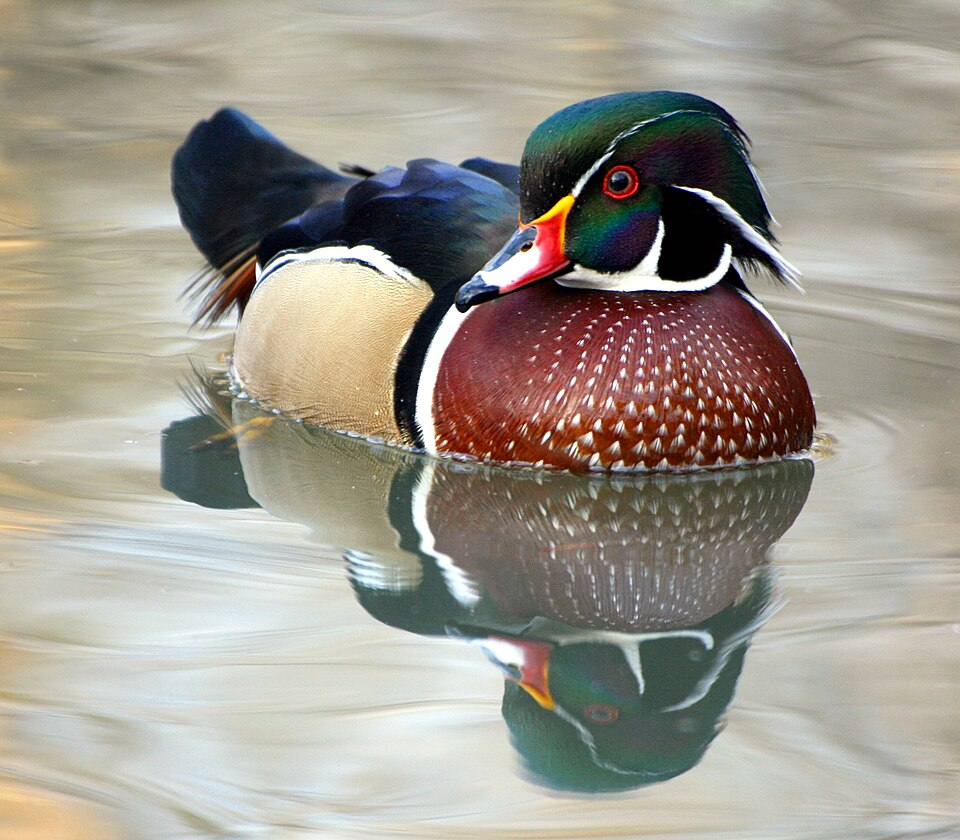 | 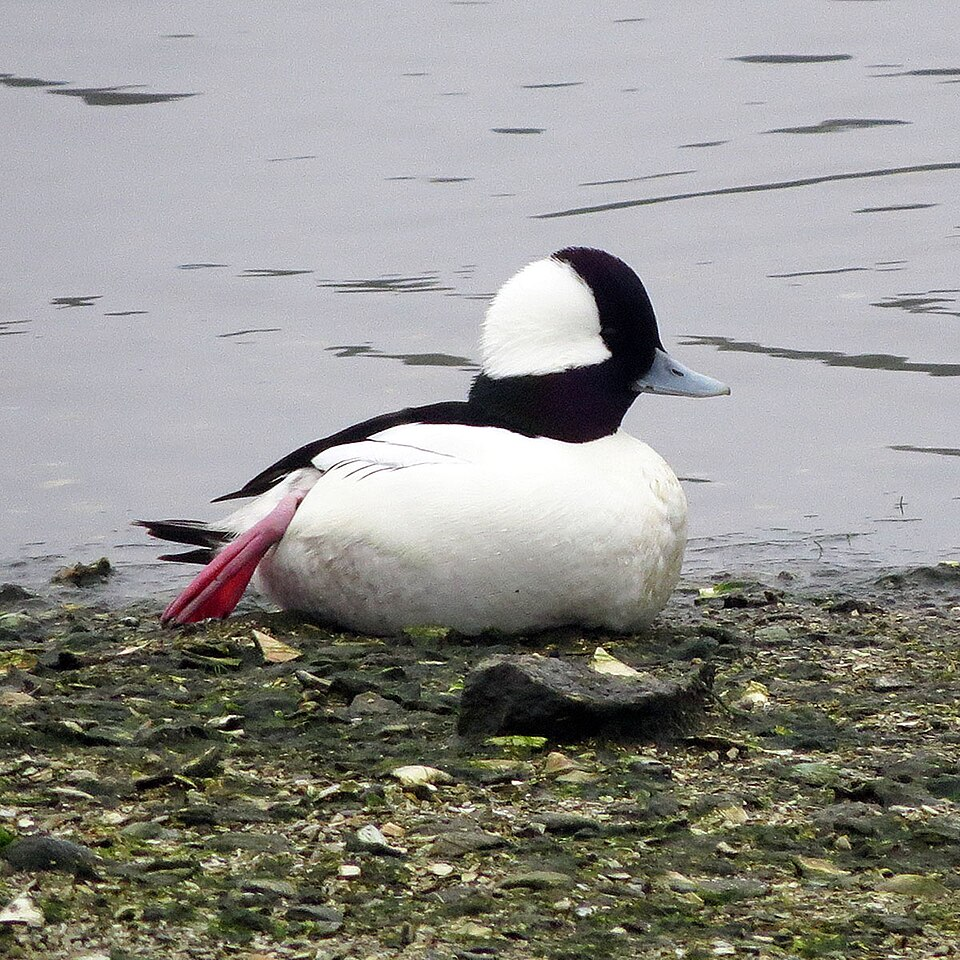 | 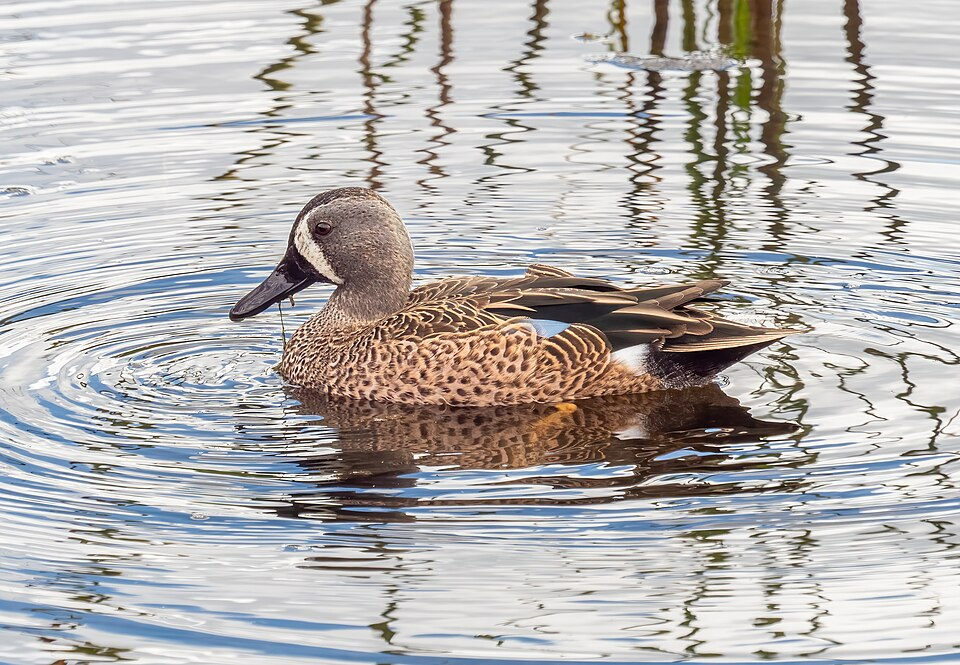 |
| *Aix sponsa* | *Bucephala albeola* | *Spatula discors* |
| **A broad annual presence.** The Virginia model stays above zero through summer, with its largest peak in March. | **A winter concentration.** Modeled abundance drops close to zero in summer and climbs sharply late in the year. | **Two seasonal pulses.** The Virginia model rises in spring and again in fall. |
| Photo: [law keven](https://commons.wikimedia.org/wiki/File:Aix_sponsa_male.jpg) · [CC BY-SA 2.0](https://creativecommons.org/licenses/by-sa/2.0) | Photo: [Don Faulkner](https://commons.wikimedia.org/wiki/File:Bufflehead_(male)_(16255698348).jpg) · [CC BY-SA 2.0](https://creativecommons.org/licenses/by-sa/2.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Blue-winged_teal_(94829).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) |

Species portraits, not photographs of the analyzed Virginia records. These images show males; females and nonbreeding plumage can look different. [Photo sources and reuse licenses](images/species/README.md).


### Three findings to follow

- **Different ducks, different calendars.** The curves reveal a winter concentration, a broad annual presence, and two seasonal pulses within the same state. The dates describe the 2023 model; they are not arrival forecasts.
- **A diverse observation snapshot.** The spatially filtered dataset contains **580 records across 29 duck species**. Mallard leads with 168 records, but Hooded Merganser contributes 71 and Wood Duck 47.
- **A named place emerges from the join.** In this saved run, **Burke Lake has 38 nearby records covering 14 duck species** within 500 m of its mapped water geometry. This is a result of joining coordinates to water polygons, not a claim about access or bird numbers.

The useful connection is **species → season → place**. Two TypeScript workers
make it queryable in one DuckDB session:
[vgi-ducks](https://github.com/Query-farm/vgi-ducks) supplies taxonomy, seasonal
ranges, and weekly abundance; the
[Overture worker](https://github.com/Query-farm/vgi-overture-maps-typescript)
supplies Virginia's boundary and water polygons. Public iNaturalist records via
GBIF supply the observation coordinates.

The final worked example combines all three sources: a chosen duck's seasonal
range, named Overture water, and nearby same-species reports. Change one settings
cell to ask the question for a different prepared species, season, or map window.


## Bird data and geography in one SQL session

**VGI makes external data queryable as ordinary SQL tables and functions.**
This notebook attaches two TypeScript workers to DuckDB:

| Source | What it contributes | What SQL does with it |
| --- | --- | --- |
| **vgi-ducks** | Duck taxonomy, seasonal range polygons, weekly abundance, peak weeks | Filter species, summarize a polygon, join ranges to water |
| **Overture worker** | Virginia's boundary and named water polygons | Clip to Virginia and measure distances in meters |
| **iNaturalist / GBIF snapshot** | Historical observation coordinates and dates | Match species and count nearby reports |

After the hidden extension installation, this is the complete duck-worker attachment.
The Overture checkout is attached in the same session by the hidden setup.
Python retrieves the public observation snapshot and draws figures; the analytical
joins and aggregations below run in SQL.


In [3]:
%%sql
 ATTACH 'ducks' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-ducks@v0.1.0');


,Success


### Change the question

The three-species overview stays fixed for comparison. These settings control
the later regional comparison, peak calendar, and final range–water–report join.
Change them in the source notebook and rerun all cells.

- `demo_species`: `buffle`, `wooduc`, or `buwtea`, the products loaded here.
- `demo_season`: `nonbreeding`, `breeding`, `prebreeding_migration`, or `postbreeding_migration`.
- `demo_focus`: `Northern Virginia`, `Richmond`, or `Hampton Roads`.
- `comparison_longitude`: the meridian splitting Virginia into two study regions.

The optional live example uses its own search coordinates. Additional species
require loading and checking their model products; the three options are this
notebook's prepared comparison set.


In [4]:
%%sql
 SET VARIABLE demo_species = 'buffle';
 SET VARIABLE demo_season = 'nonbreeding';
 SET VARIABLE demo_focus = 'Northern Virginia';
 SET VARIABLE comparison_longitude = -77.3;
 SET VARIABLE live_latitude = 38.76;
 SET VARIABLE live_longitude = -77.30;


,Success


## 1. Use Virginia's boundary, not just a rectangular search

A record labeled “Virginia” can lie across a state line or in neighboring waters.
We retrieve both the land and territorial versions of Virginia from Overture,
then keep duck coordinates covered by its **territorial** boundary. The land
polygon gives the maps a coastline.

The four bounding-box predicates below constrain the Overture scan. Its catalog
enforces them before DuckDB reads the GeoParquet data.


In [6]:
%%sql
CREATE TEMP TABLE virginia AS
SELECT id, names.primary AS name, is_land, is_territorial, geometry
FROM overture.divisions.division_area
WHERE bbox.xmin BETWEEN -84 AND -75 AND bbox.xmax BETWEEN -84 AND -75
  AND bbox.ymin BETWEEN 36 AND 40 AND bbox.ymax BETWEEN 36 AND 40
  AND subtype = 'region' AND country = 'US' AND region = 'US-VA';

SELECT name, is_land, is_territorial,
       round(ST_Area_Spheroid(geometry) / 1000000) AS area_km2
FROM virginia ORDER BY is_territorial DESC;


,name,is_land,is_territorial,area_km2
0,Virginia,False,True,110757.0
1,Virginia,True,False,104738.0


The input is restricted to one source dataset, human observations marked present,
2024–2025 dates, known coordinate uncertainty of **250 m or less**, no GBIF-flagged
geospatial issue, and record licenses CC0 or CC BY. These filters create a selected
public-record dataset; they do not establish complete coverage of Virginia.

The SQL join below uses the worker's extant duck catalog to exclude geese, swans,
and names that do not match. GBIF's accepted species names are matched exactly;
there is no guessed mapping between taxonomies. A second spatial filter removes
coordinates outside the state.


In [7]:
%%sql
CREATE TEMP TABLE input_records AS
SELECT * FROM read_json(getvariable('observations_file'));

CREATE TEMP TABLE matched_ducks AS
SELECT r.*, s.common_name, s.species_code,
       ST_Point(r.longitude, r.latitude) AS point
FROM input_records AS r
JOIN ducks.main.species AS s
  ON r.scientific_name = s.scientific_name AND NOT s.extinct
WHERE try_cast(r.observation_date AS DATE) IS NOT NULL;

CREATE TEMP TABLE virginia_ducks AS
SELECT r.* FROM matched_ducks AS r
WHERE EXISTS (
  SELECT 1 FROM virginia AS v
  WHERE v.is_territorial AND ST_Covers(v.geometry, r.point)
);

SELECT (SELECT count(*) FROM input_records) AS eligible_waterfowl_records,
       (SELECT count(*) FROM matched_ducks) AS duck_catalog_matches,
       count(*) AS duck_records_inside_virginia,
       count(DISTINCT species_code) AS duck_species
FROM virginia_ducks;


,eligible_waterfowl_records,duck_catalog_matches,duck_records_inside_virginia,duck_species
0,800,582,580,29


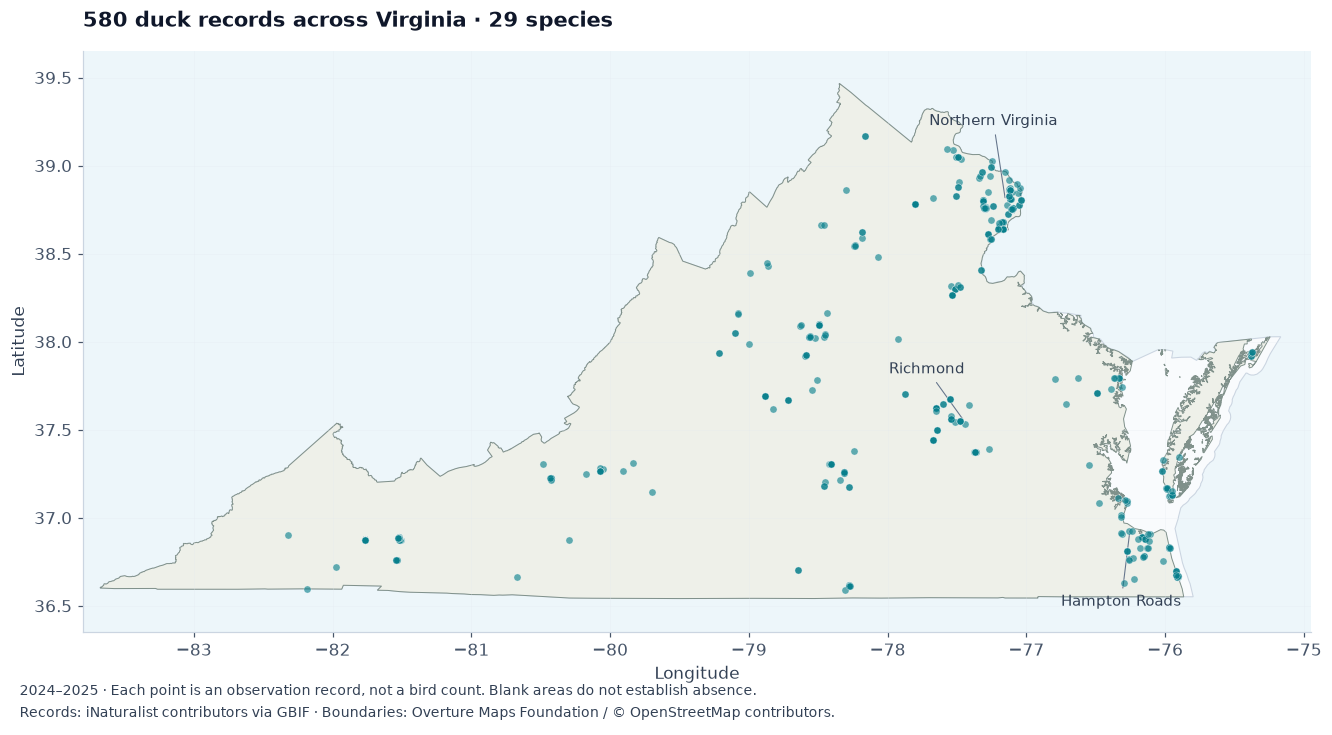

## 2. Which ducks appear in these records?

The ranking describes **retained observation records in this source**, not which
species is most abundant in Virginia. Birders' locations, identification habits,
photographs, and licensing choices all influence the records available here.


### Put faces to three of the frequently reported species

| **Mallard** | **Hooded Merganser** | **Gadwall** |
| --- | --- | --- |
| 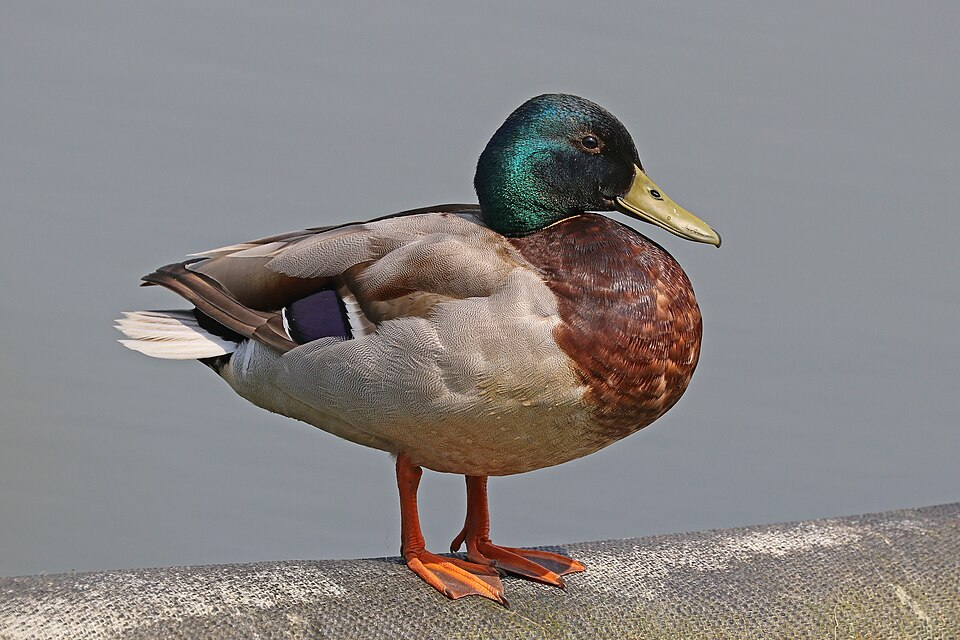 | 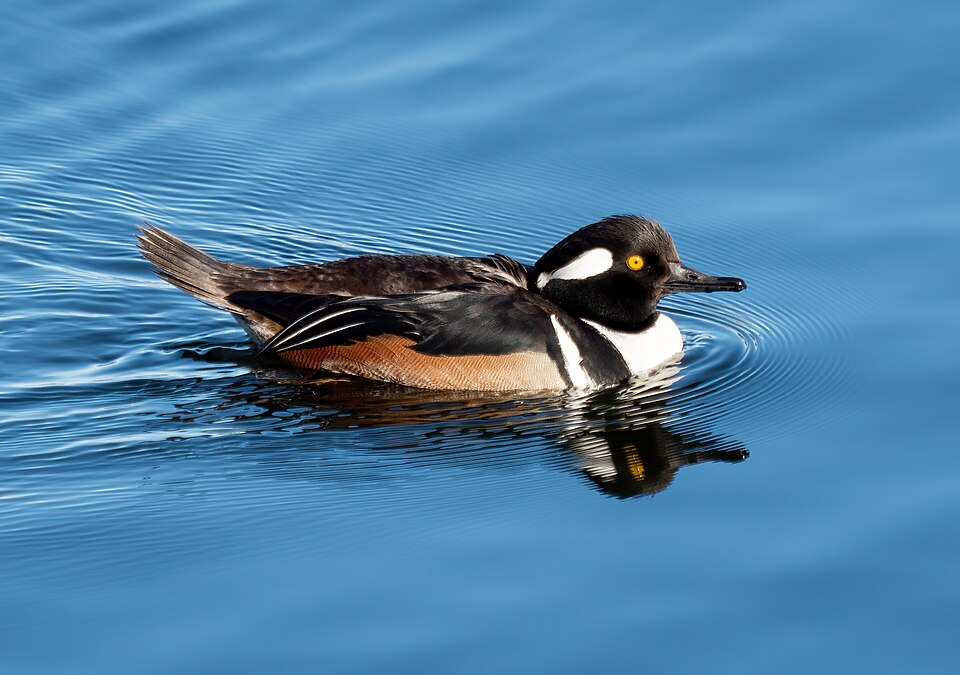 | 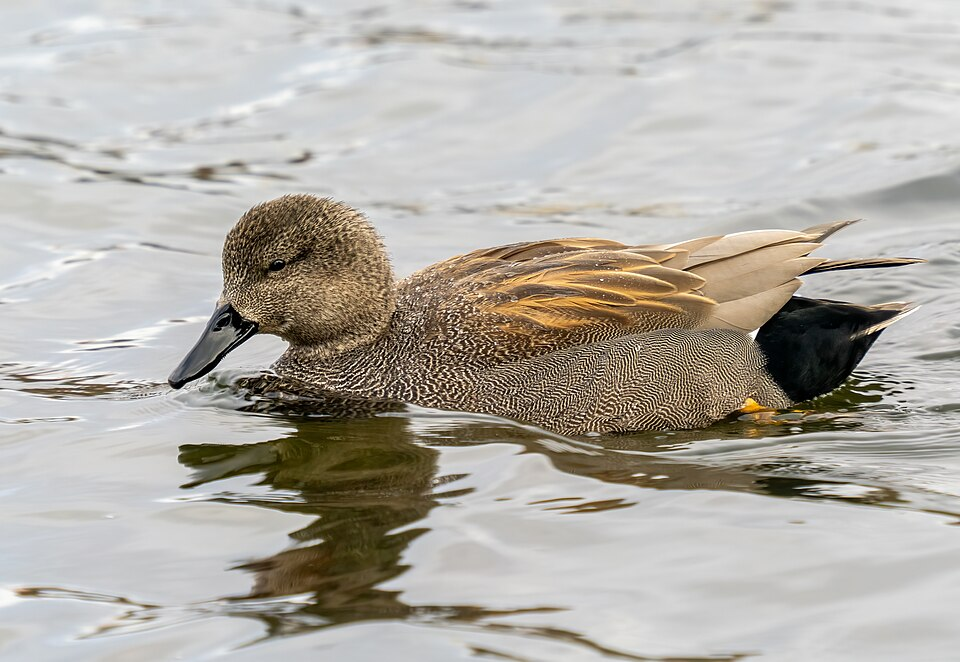 |
| *Anas platyrhynchos* | *Lophodytes cucullatus* | *Mareca strepera* |
| **Mallard:** 168 retained records. | **Hooded Merganser:** 71 retained records. | **Gadwall:** 29 retained records. |
| Photo: [Charles J. Sharp](https://commons.wikimedia.org/wiki/File:Mallard_duck_(Anas_platyrhynchos)_male.jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Hooded_merganser_male_in_CP_(40620).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) | Photo: [Rhododendrites](https://commons.wikimedia.org/wiki/File:Gadwall_male_(00043).jpg) · [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0) |

Species portraits, not photographs of the analyzed Virginia records. These images show males; females and nonbreeding plumage can look different. [Photo sources and reuse licenses](images/species/README.md).


In [11]:
%%sql species_counts <<
SELECT common_name, scientific_name, species_code, count(*) AS records,
       count(DISTINCT observation_month) AS months_with_records
FROM virginia_ducks
GROUP BY ALL
ORDER BY records DESC, common_name;


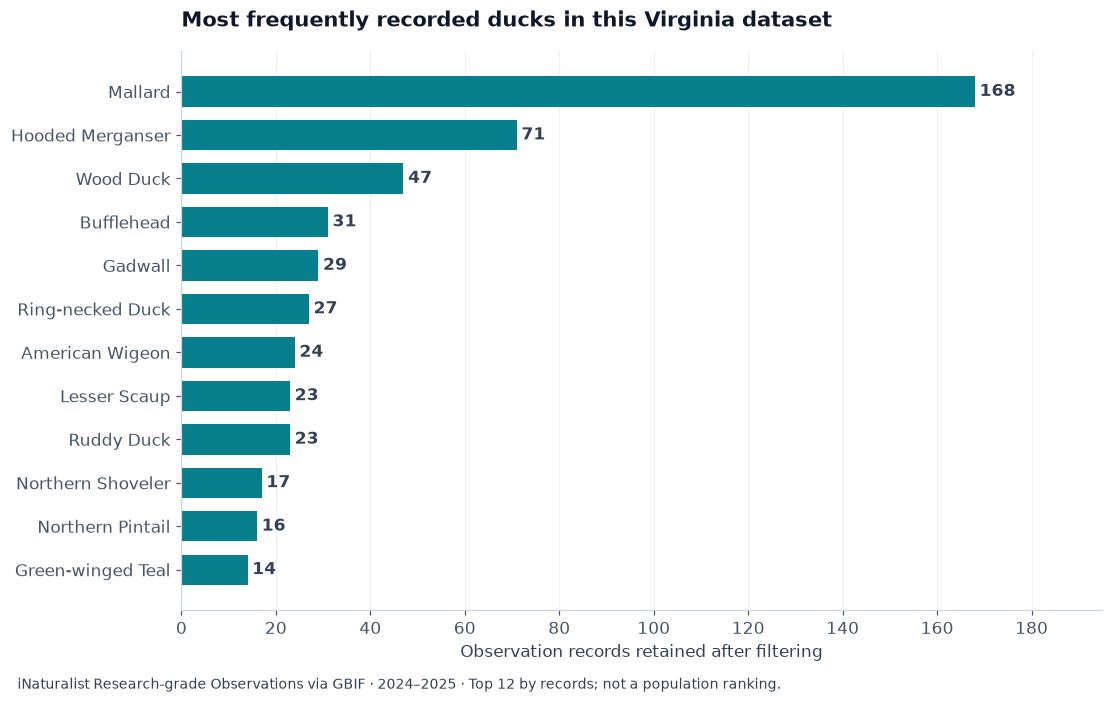

## 3. How do the reported seasons differ?

We count records by species and calendar month across two complete years.
The heatmap compares each species with its own annual total: **color is the
percentage of that species' records in the month; cell numbers are record counts**.
A zero means no retained record in this dataset, not that the duck was absent.

These are descriptive reporting patterns. They do not control for observer
effort and must not be read as migration probabilities or arrival dates.


In [13]:
%%sql monthly <<
SELECT common_name, observation_month AS month, count(*) AS records
FROM virginia_ducks
GROUP BY common_name, observation_month
ORDER BY common_name, month;


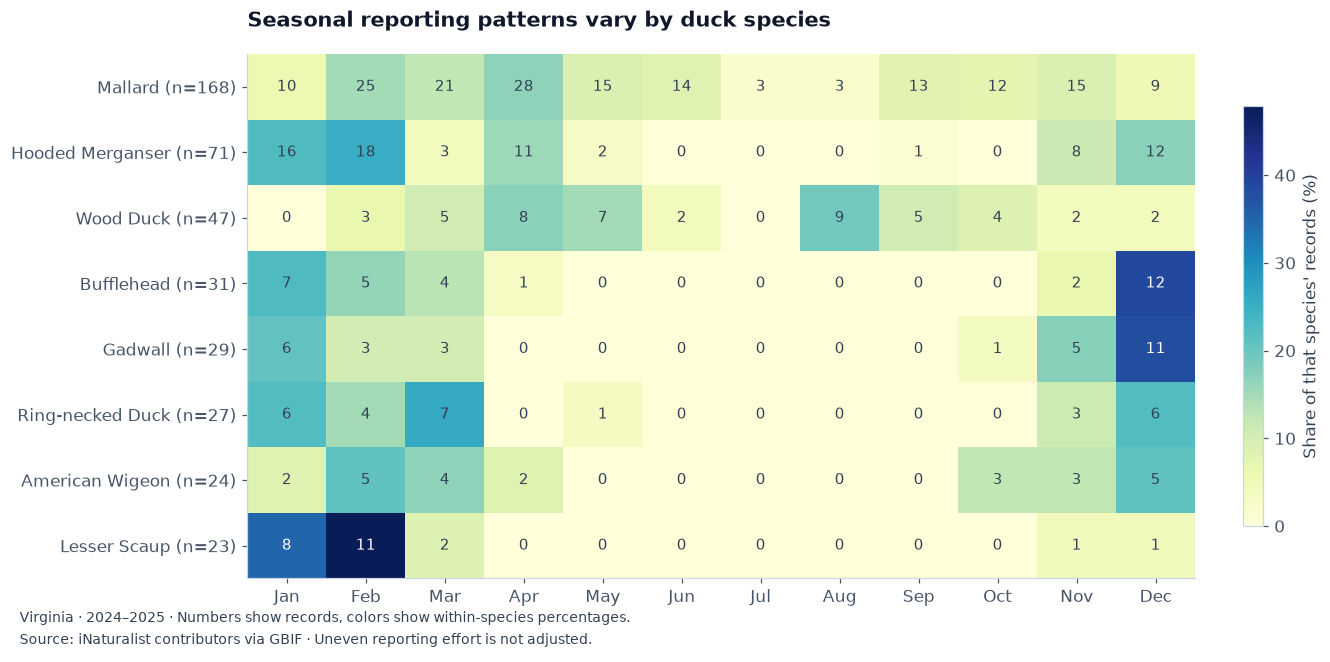

### Why focus the model section on these three ducks?

We selected a small comparison set to explain the method and show contrasting
seasonal patterns. It is **not a random sample, a popularity ranking, or a
representative sample of all Virginia ducks**.

| Species | What this example helps us see in the 2023 Virginia model |
| --- | --- |
| Wood Duck | A broad annual presence, including summer, with a larger spring peak |
| Bufflehead | A strong winter concentration and a much smaller summer signal |
| Blue-winged Teal | Distinct spring and fall pulses |

All three have verified 2023 weekly and seasonal-range products at the chosen
27 km resolution, and all four model seasons passed Cornell's review at quality 3.
Keeping three species also keeps the seasonal comparison to twelve map panels.

The observation analysis above still includes all **29 matched species** in this
snapshot. Mallard leads those records but was not included in this curated model
comparison. The worker can query other species with available Status products;
we have not evaluated model availability or quality for all 29 here.


## 4. What does mean relative abundance mean?

**Think of the model's expected number of birds detected on a standard birding
checklist, averaged across the selected Virginia grid cells for one week.**

Cornell standardizes the checklist to **one hour of traveling over two kilometers**,
with an expert observer at the optimal time of day and weather for detecting
that species. The result is an expected detection count, not a census of every
bird present. The downloaded weekly product uses the median prediction from
Cornell's model ensemble. [Definition and product details](https://ebird.github.io/ebirdst/articles/status.html#weekly-raster-estimates).

The two parts of the name matter:

- **Relative abundance** is this standardized detection-based measure. “Relative” does not mean a percentage of all ducks or a probability of seeing one.
- **Mean** is the spatial average across modeled cells inside our Virginia polygon, calculated separately for each species and week. It is not an average across species, across the year, or across the observation records.

```text
mean_relative_abundance = sum of the selected cell predictions / number of modeled cells
```

Each modeled cell receives equal weight. Real zero predictions stay in the
average; cells with no prediction (NoData) are excluded, rather than treated as
zero. The separate coverage measure tells us how many selected cells contributed.


### A small worked example

These are **illustrative numbers, not Virginia observations or model results**.
Suppose one species in one week has the following predictions:

| Selected grid cell | A | B | C | D | E |
| --- | ---: | ---: | ---: | ---: | --- |
| Predicted detections per standard checklist | 0.0 | 0.2 | 0.4 | 0.6 | NoData |

The mean is **(0.0 + 0.2 + 0.4 + 0.6) / 4 = 0.3** predicted detections per
standard checklist, averaged across the four modeled cells. Coverage is **4 / 5
= 80%**. Dropping the zero would incorrectly inflate the mean; replacing NoData
with zero would incorrectly lower it.

Fractional predictions describe an expectation: an actual checklist can record
zero, one, or several birds. **0.3 is not a 30% chance of seeing a duck.**
Encounter probability is a different quantity.

### Read an actual value from the chart

The Bufflehead curve reaches about **1.57 on December 27, 2023**. Here that means
1.57 predicted detections per standard checklist, averaged across the **149
modeled cells** selected for Virginia. It does not mean 1.57 birds inhabit each
cell, 157% probability, or a statewide total obtained by multiplying by 149.
It also does not predict a particular visit to Burke Lake.

Use each species' curve to examine **how its modeled seasonal signal changes**.
Do not use the heights of different species' curves to rank their populations:
detectability differs between species, even after effort is standardized.
[Cornell's guidance on comparisons across species](https://ebird.github.io/ebird-one-day-status-workshop/ebirdst.html).


This run averages **149 selected 27 km cells** for each species. All contribute
in every week; 100% coverage measures data availability, not certainty.
The model year is 2023, separate from the 2024–2025 observation snapshot.
[Grid selection and boundary details](#Grid-selection-and-coverage) are in the appendix.


In [15]:
%%sql
CREATE TEMP TABLE model_region AS
SELECT ST_SimplifyPreserveTopology(geometry,0.01) AS geometry
FROM virginia WHERE is_territorial;
SET VARIABLE virginia_wkt = (SELECT ST_AsText(geometry) FROM model_region);
SELECT ST_NPoints(geometry) AS vertices, ST_IsValid(geometry) AS valid,
       round(ST_Area(ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true))/1e6) AS area_km2
FROM model_region;


,vertices,valid,area_km2
0,181,True,110279.0


In [16]:
%%sql
CREATE TEMP TABLE weekly_models AS
SELECT 'Wood Duck' AS common_name, * FROM ducks.main.weekly_abundance(
  'wooduc', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Bufflehead' AS common_name, * FROM ducks.main.weekly_abundance(
  'buffle', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km')
UNION ALL
SELECT 'Blue-winged Teal' AS common_name, * FROM ducks.main.weekly_abundance(
  'buwtea', getvariable('virginia_wkt'), data_year:=2023, resolution:='27km');

SELECT common_name, count(*) AS weeks,
       min(selected_cell_count) AS selected_cells,
       round(min(coverage_fraction),3) AS minimum_coverage,
       round(max(coverage_fraction),3) AS maximum_coverage
FROM weekly_models GROUP BY common_name ORDER BY common_name;


,common_name,weeks,selected_cells,minimum_coverage,maximum_coverage
0,Blue-winged Teal,52,149,1.0,1.0
1,Bufflehead,52,149,1.0,1.0
2,Wood Duck,52,149,1.0,1.0


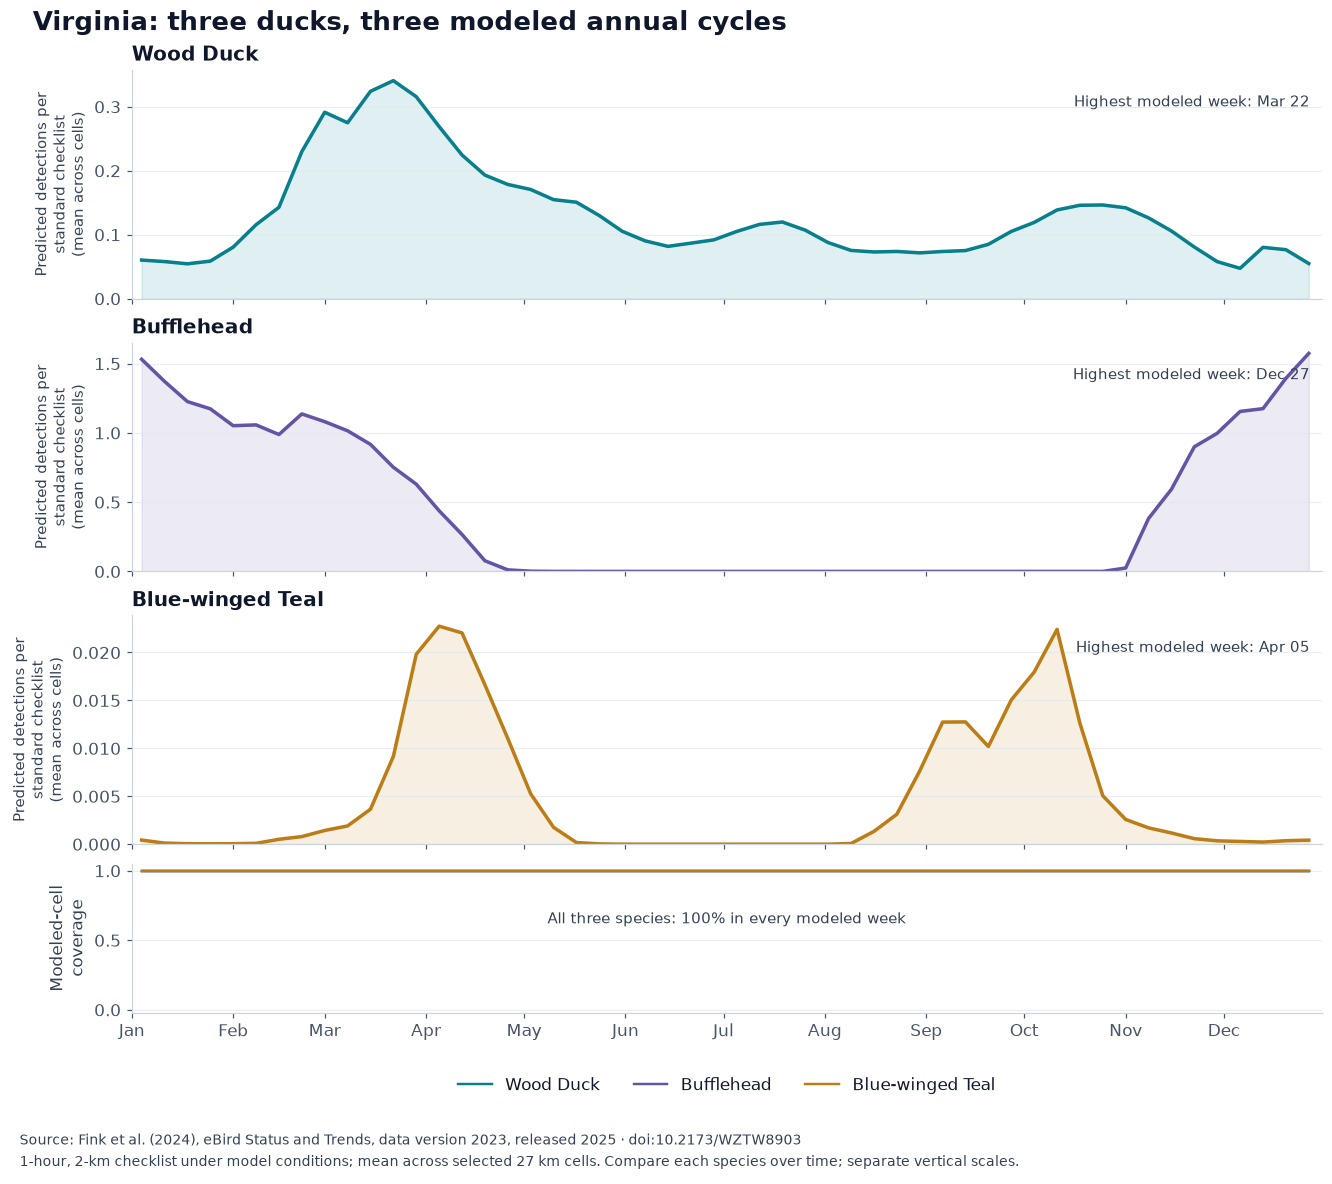

### What the curves reveal

**Bufflehead changes the most visibly across seasons:** its Virginia curve is
high in winter and close to zero through summer. **Blue-winged Teal has two
separate pulses**, with its highest modeled week on April 5 and another rise in
fall. **Wood Duck has a broader annual presence**, with a March 22 peak and
positive values through summer.

Those shapes are more useful than a single peak date: they distinguish seasonal
concentration from a broader annual presence. The three panels have different
vertical scales. Compare seasonal timing; their raw heights do not establish
population differences between species because detectability also differs. Every selected cell has a modeled value in this run; the flat 100%
coverage line does not imply zero model uncertainty.


### Change the polygon: does the statewide curve hide regional differences?

The same function accepts **any supported polygon**. We split Virginia at the
configured longitude and query the same species in each half. These are explicitly
defined study regions, not official ecological regions. The map shows exactly
what each curve summarizes. Both curves share one vertical scale because they
describe the same species; cell counts and coverage remain visible.


In [19]:
%%sql
 CREATE TEMP TABLE comparison_regions AS
 SELECT side, ST_Intersection(v.geometry, box) AS geometry
 FROM model_region v CROSS JOIN (VALUES
   ('Central & western Virginia', ST_MakeEnvelope(-84,36,getvariable('comparison_longitude'),40)),
   ('Eastern Virginia', ST_MakeEnvelope(getvariable('comparison_longitude'),36,-74,40))
 ) AS regions(side,box);
 SET VARIABLE west_wkt = (SELECT ST_AsText(geometry) FROM comparison_regions WHERE side='Central & western Virginia');
 SET VARIABLE east_wkt = (SELECT ST_AsText(geometry) FROM comparison_regions WHERE side='Eastern Virginia');

 CREATE TEMP TABLE regional_weekly AS
 SELECT 'Central & western Virginia' AS region, * FROM ducks.main.weekly_abundance(
   getvariable('demo_species'), getvariable('west_wkt'), data_year:=2023, resolution:='27km')
 UNION ALL
 SELECT 'Eastern Virginia' AS region, * FROM ducks.main.weekly_abundance(
   getvariable('demo_species'), getvariable('east_wkt'), data_year:=2023, resolution:='27km');

 SELECT region, count(*) AS weeks, min(selected_cell_count) AS selected_cells,
        round(min(coverage_fraction),3) AS minimum_coverage
 FROM regional_weekly GROUP BY region ORDER BY region;


,region,weeks,selected_cells,minimum_coverage
0,Central & western Virginia,52,114,1.0
1,Eastern Virginia,52,35,1.0


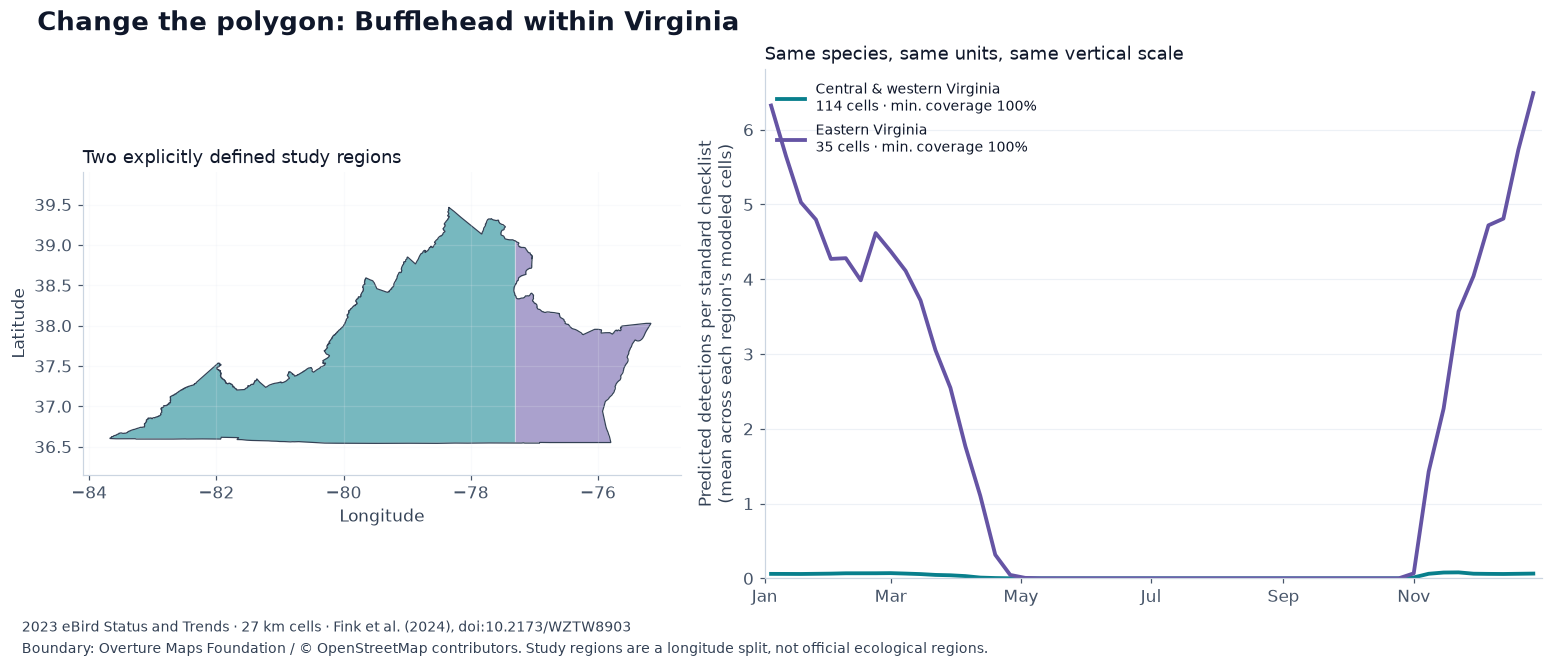

For **Bufflehead**, the same model produces different regional curves: **Central & western Virginia: 0.08** predicted detections per standard checklist at its highest modeled week (Nov 22); **Eastern Virginia: 6.49** predicted detections per standard checklist at its highest modeled week (Dec 27). These are means over each region’s modeled cells, not predictions for a particular lake. The mapped split makes a pattern hidden by the statewide average visible.

### Ask the worker for the peak week

`migration_calendar` returns every week tied for the **highest positive regional
mean**. Here it summarizes the selected species across Virginia. Its name does
not make the result an arrival date: winter residence or breeding can cause a peak.
The validation compares these rows with the maximum of the full weekly series.


In [23]:
%%sql
 CREATE TEMP TABLE selected_peak AS
 SELECT * FROM ducks.main.migration_calendar(
   getvariable('demo_species'), getvariable('virginia_wkt'), data_year:=2023, resolution:='27km');
 SELECT s.common_name, p.week_date, round(p.mean_relative_abundance,4) AS mean_relative_abundance,
        modeled_cell_count, coverage_fraction
 FROM selected_peak p JOIN ducks.main.species s USING(species_code) ORDER BY p.week_date;


,common_name,week_date,mean_relative_abundance,modeled_cell_count,coverage_fraction
0,Bufflehead,2023-12-27,1.5731,149,1.0


### Join seasonal range polygons to the state

The maps below show **where each species' modeled seasonal range overlaps
Virginia**. Each species gets the same four panels: nonbreeding, spring
migration, breeding, and fall migration. Pale color shows the range around the
state; stronger color highlights the part inside Virginia's dark outline.
Roanoke, Richmond, and Norfolk provide geographic reference points.

The map labels and table use the **same spatial intersection** to measure the
percentage of Virginia's territory intersected by each smoothed range. Shading
shows modeled range extent, not bird density, confirmed sightings, or suitable
habitat. The 27 km source polygons are coarse, so small bays and wetlands are
below their useful detail.

Season dates describe Cornell's species-wide model seasons; they are not
Virginia-specific arrival and departure dates. Winter dates can wrap New Year.


In [24]:
%%sql
CREATE TEMP TABLE seasonal_models AS
SELECT * FROM ducks.main.seasonal_ranges('wooduc',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buffle',data_year:=2023,resolution:='27km')
UNION ALL
SELECT * FROM ducks.main.seasonal_ranges('buwtea',data_year:=2023,resolution:='27km');

CREATE TEMP TABLE seasonal_range_overlays AS
WITH intersections AS (
  SELECT r.species_code, r.common_name, r.season, r.start_date, r.end_date, r.wraps_year,
         ST_Intersection(ST_GeomFromWKB(r.geometry_wkb),v.geometry) AS virginia_geometry,
         ST_Intersection(ST_GeomFromWKB(r.geometry_wkb),
           ST_MakeEnvelope(-84.1,36.15,-74.7,39.9)) AS context_geometry,
         ST_Area(ST_Transform(v.geometry,'OGC:CRS84','EPSG:26918',always_xy:=true)) AS state_area_m2
  FROM seasonal_models r CROSS JOIN virginia v WHERE v.is_territorial
)
SELECT *, 100 * ST_Area(ST_Transform(virginia_geometry,
         'OGC:CRS84','EPSG:26918',always_xy:=true)) / state_area_m2 AS virginia_territory_percent
FROM intersections;

SELECT common_name, season, start_date, end_date, wraps_year,
       round(virginia_territory_percent,1) AS virginia_territory_percent
FROM seasonal_range_overlays ORDER BY common_name,season;


,common_name,season,start_date,end_date,wraps_year,virginia_territory_percent
0,Blue-winged Teal,breeding,2023-06-14,2023-07-12,False,0.0
1,Blue-winged Teal,nonbreeding,2023-12-27,2023-01-25,True,1.2
2,Blue-winged Teal,postbreeding_migration,2023-07-19,2023-12-20,False,64.4
3,Blue-winged Teal,prebreeding_migration,2023-02-01,2023-06-07,False,75.7
4,Bufflehead,breeding,2023-06-07,2023-07-19,False,0.8
5,Bufflehead,nonbreeding,2023-12-27,2023-02-15,True,64.0
6,Bufflehead,postbreeding_migration,2023-07-26,2023-12-20,False,87.8
7,Bufflehead,prebreeding_migration,2023-02-22,2023-05-31,False,77.3
8,Wood Duck,breeding,2023-04-26,2023-06-21,False,96.4
9,Wood Duck,nonbreeding,2023-12-06,2023-01-25,True,86.0


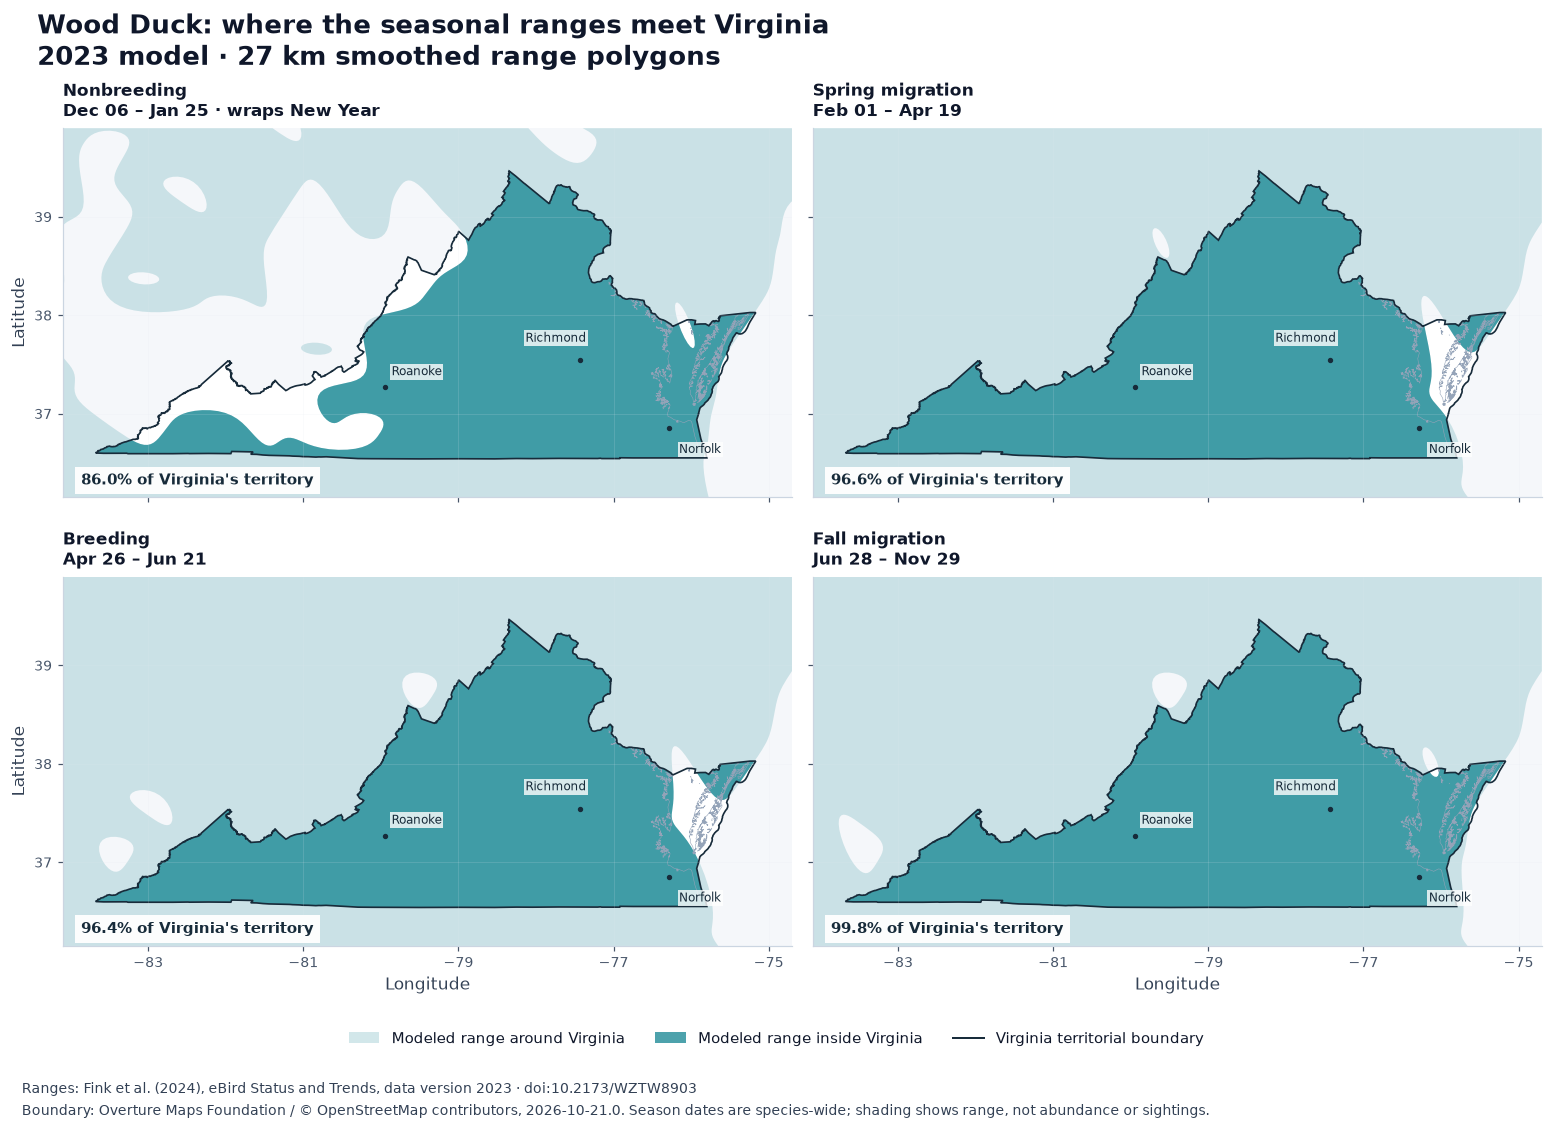

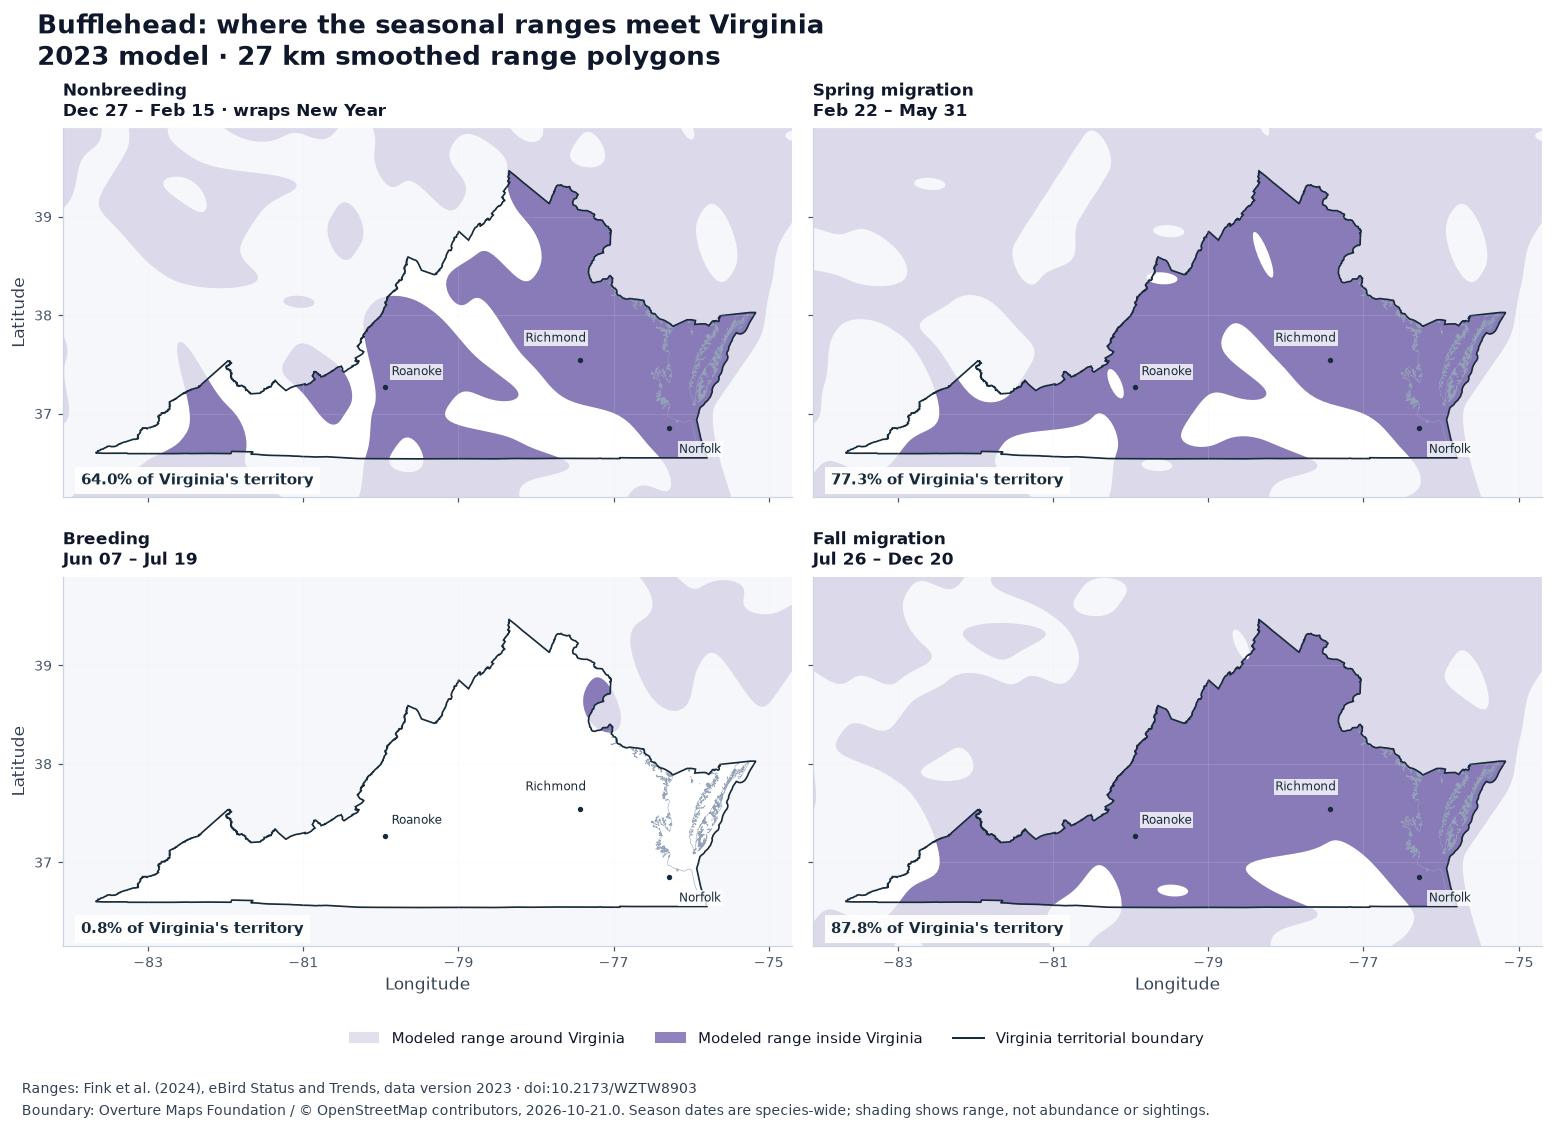

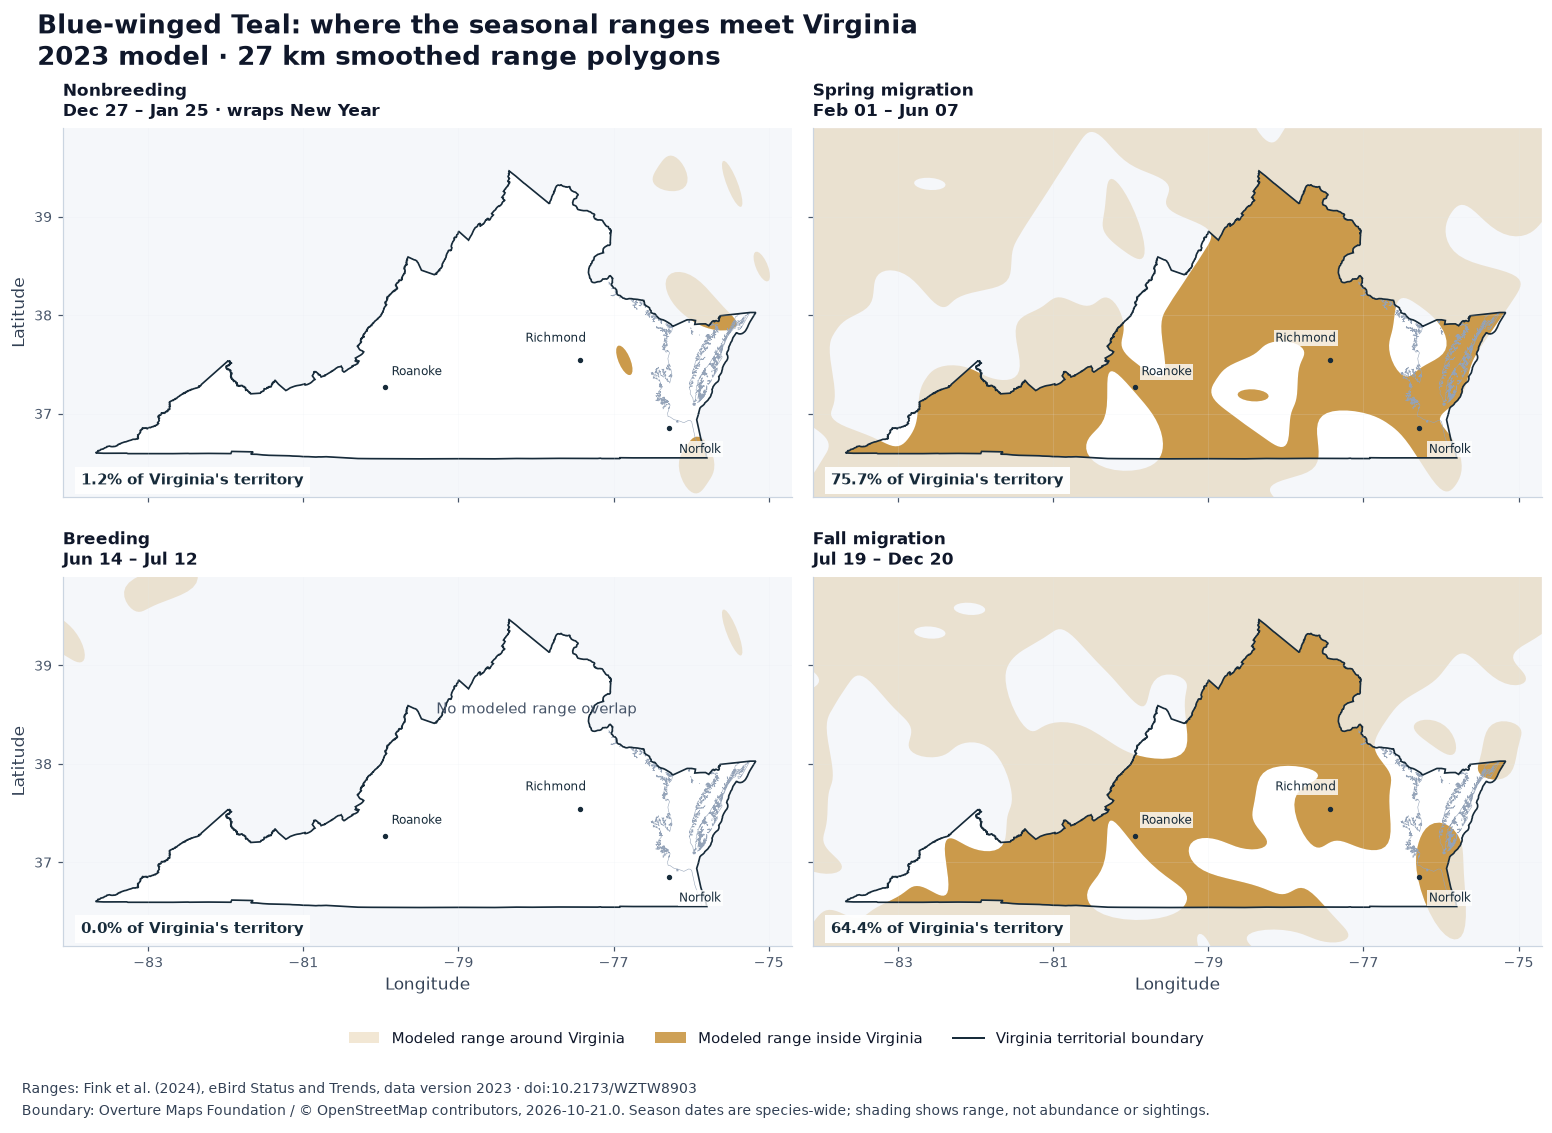

### Read the geography as well as the calendar

All twelve maps share an extent and scale. Darker shading is the modeled range
intersected with Virginia, including coastal waters. Percentage labels preserve
overlaps too small to see easily. A blank panel means no modeled polygon overlap;
individual birds can still occur there. Geometry and validation details are in
the appendix.


## 5. Put the duck records beside mapped water

Overture adds context that the bird records do not contain. We inspect three
bounded windows: **Northern Virginia, Richmond, and Hampton Roads**. The query
below retains overlapping water polygons, including coastal water, and excludes
swimming pools, drains, and wastewater features.

These are mapped water features, **not a habitat-suitability or public-access map**.
Some wetlands and seasonal water are missing. Water boundaries come from the
2026 Overture release, while the observations are from 2024–2025.


In [30]:
%%sql
CREATE TEMP TABLE local_water AS
SELECT 'Northern Virginia' AS focus, id, names.primary AS name, subtype, class, geometry
FROM overture.base.water
WHERE bbox.xmin <= -76.95 AND bbox.xmax >= -77.4
  AND bbox.ymin <= 39.05 AND bbox.ymax >= 38.55
  AND ST_GeometryType(geometry) IN ('POLYGON','MULTIPOLYGON')
  AND (subtype IN ('lake','pond','river','stream','ocean')
       OR (subtype='water' AND class='water')
       OR (subtype='reservoir' AND class='reservoir'));


,Success


### Ask a spatial question, with distances in meters

Which records lie within **500 m** of mapped water? The SQL projects coordinates
into meters and uses `EXISTS` to count each observation once, even when water
features overlap. With coordinate uncertainty up to 250 m, proximity provides
context rather than proof of habitat use or public access.


In [32]:
%%sql
CREATE TEMP TABLE water_m AS
SELECT *, ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true) AS geom_m
FROM local_water;

CREATE TEMP TABLE focus_records AS
SELECT f.name AS focus, r.*,
       ST_Transform(r.point,'OGC:CRS84','EPSG:26918',always_xy:=true) AS point_m
FROM virginia_ducks AS r JOIN focus_regions AS f
  ON r.longitude BETWEEN f.west AND f.east
 AND r.latitude BETWEEN f.south AND f.north;

CREATE TEMP TABLE water_context AS
SELECT r.*, EXISTS (
  SELECT 1 FROM water_m AS w
  WHERE w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
) AS within_500m_of_mapped_water
FROM focus_records AS r;

SELECT focus, count(*) AS records, count(DISTINCT species_code) AS duck_species,
       count(*) FILTER (WHERE within_500m_of_mapped_water) AS records_near_water
FROM water_context GROUP BY focus ORDER BY focus;


,focus,records,duck_species,records_near_water
0,Hampton Roads,64,15,62
1,Northern Virginia,206,19,183
2,Richmond,29,13,28


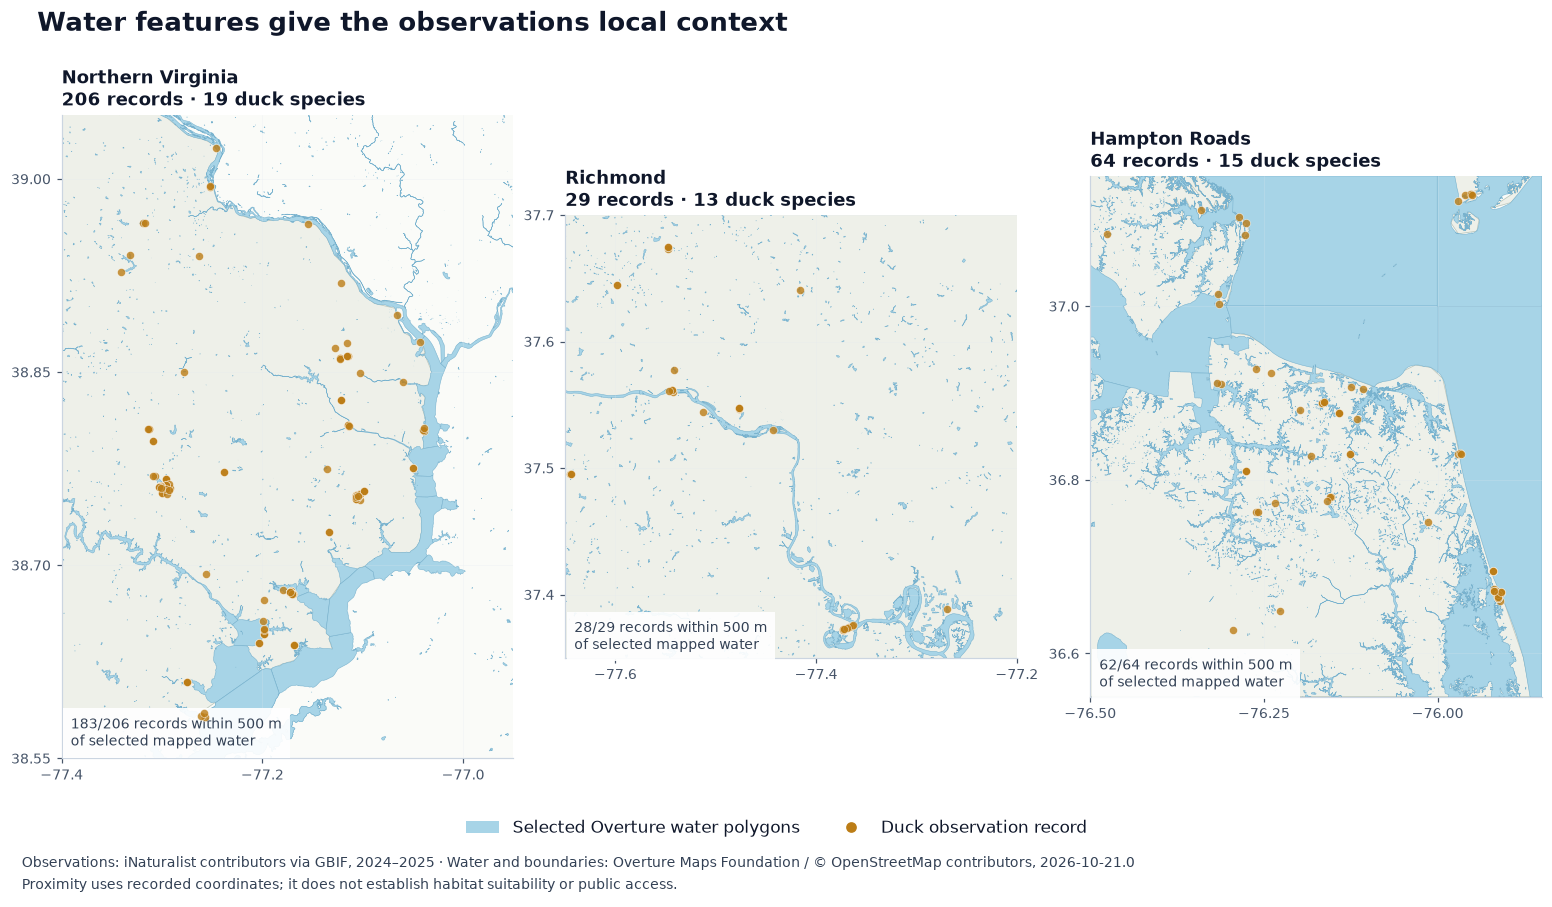

### Connect records to named water features

This final join lists named features with nearby records in the three windows.
A record can appear near more than one named feature, so these counts must not be
summed to obtain a total. They describe spatial proximity, not visitor access or
confirmed use of a particular water body.


In [36]:
%%sql
SELECT w.focus, w.name AS water_feature,
       count(DISTINCT r.gbif_id) AS nearby_records,
       count(DISTINCT r.species_code) AS duck_species
FROM water_m AS w JOIN focus_records AS r
  ON w.focus=r.focus AND ST_DWithin(w.geom_m,r.point_m,500)
WHERE w.name IS NOT NULL
GROUP BY w.focus,w.name
ORDER BY nearby_records DESC,w.focus,water_feature
LIMIT 10;


,focus,water_feature,nearby_records,duck_species
0,Northern Virginia,Burke Lake,38,14
1,Northern Virginia,Pohick Bay,18,10
2,Hampton Roads,Lake Smith,8,5
3,Northern Virginia,Belmont Bay,8,5
4,Northern Virginia,Cameron Run,6,3
5,Northern Virginia,Sparrow Pond,5,1
6,Hampton Roads,Lake Lawson,4,3
7,Hampton Roads,Lake Rudee,4,3
8,Hampton Roads,Lake Wesley,4,3
9,Hampton Roads,Rudee Inlet,4,3


### From a coordinate to a recognizable place

**Burke Lake leads this table with 38 nearby records and 14 duck species.**
Pohick Bay follows with 18 records and 10 species. The join turns scattered
observation coordinates into a comparison of named water features that a reader
can recognize. It is also easy to audit: the visible SQL shows the 500 m distance,
the species counts, and how duplicate matches are handled.

These results apply to the filtered source and the three chosen map windows.
They describe nearby reports, not the number of birds living on each lake or bay.


## 6. Connect a species, a season, and named water

**Which named water bodies intersect the selected duck's modeled seasonal range,
and which have nearby historical reports of that same duck during those seasonal dates?**

The default example is **Bufflehead · nonbreeding · Northern Virginia**. First SQL
intersects the range with named Overture water inside the selected window and
Virginia. It then matches reports of that species within 500 m of the intersected
water. The model's month/day window is applied separately to the 2024–2025 records,
including seasons that wrap New Year. This comparison does not validate the 2023
model or establish access to a water body.


In [37]:
%%sql
 CREATE TEMP TABLE chosen_range AS
 SELECT * FROM seasonal_models
 WHERE species_code=getvariable('demo_species') AND season=getvariable('demo_season');

 CREATE TEMP TABLE seasonal_water AS
 WITH clipped AS (
   SELECT w.id, w.name, ST_Intersection(
     ST_Intersection(w.geometry,v.geometry),
     ST_Intersection(ST_GeomFromWKB(r.geometry_wkb),
       ST_MakeEnvelope(f.west,f.south,f.east,f.north))) AS geometry
   FROM local_water w JOIN focus_regions f ON w.focus=f.name
   CROSS JOIN chosen_range r CROSS JOIN virginia v
   WHERE w.focus=getvariable('demo_focus') AND w.name IS NOT NULL AND v.is_territorial
 )
 SELECT *, ST_Transform(geometry,'OGC:CRS84','EPSG:26918',always_xy:=true) AS geom_m
 FROM clipped WHERE NOT ST_IsEmpty(geometry) AND ST_Area(geometry)>0;

 CREATE TEMP TABLE seasonal_reports AS
 SELECT p.* FROM focus_records p CROSS JOIN chosen_range r
 WHERE p.focus=getvariable('demo_focus') AND p.species_code=r.species_code
   AND CASE WHEN r.wraps_year
     THEN strftime(p.observation_date::DATE,'%m-%d') >= strftime(r.start_date::DATE,'%m-%d')
       OR strftime(p.observation_date::DATE,'%m-%d') <= strftime(r.end_date::DATE,'%m-%d')
     ELSE strftime(p.observation_date::DATE,'%m-%d') BETWEEN
       strftime(r.start_date::DATE,'%m-%d') AND strftime(r.end_date::DATE,'%m-%d') END;

 CREATE TEMP TABLE water_report_matches AS
 SELECT w.id AS water_id,p.gbif_id
 FROM seasonal_water w JOIN seasonal_reports p ON ST_DWithin(w.geom_m,p.point_m,500);

 CREATE TEMP TABLE water_evidence AS
 SELECT w.*, coalesce(m.nearby_reports,0) AS nearby_reports
 FROM seasonal_water w LEFT JOIN (
   SELECT water_id,count(DISTINCT gbif_id) AS nearby_reports
   FROM water_report_matches GROUP BY water_id
 ) m ON w.id=m.water_id;

 SELECT name AS water_feature, nearby_reports
 FROM water_evidence WHERE nearby_reports>0
 ORDER BY nearby_reports DESC,name,id LIMIT 8;


,water_feature,nearby_reports
0,Belmont Bay,1
1,Pohick Bay,1


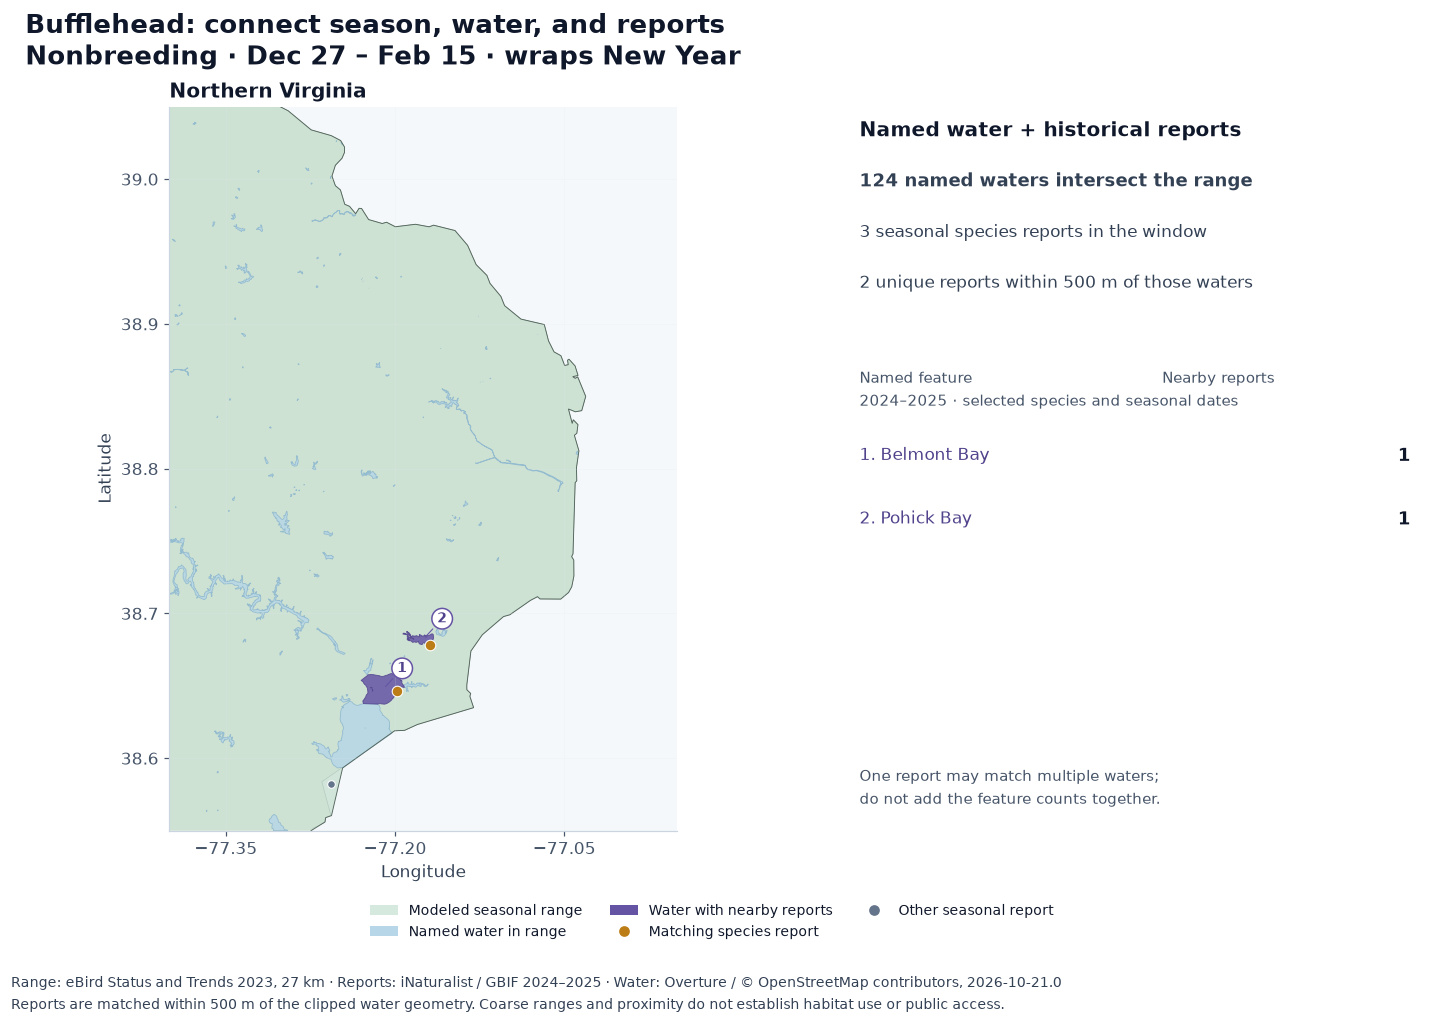

**Bufflehead · Northern Virginia:** 124 named water features intersect the selected range inside the window. 2 have nearby matching reports, covering **2 unique records** out of 3 seasonal records in the window. **Belmont Bay** has 1 nearby matching report.

A record can match several water features, so table counts must not be summed. Zero matching reports means none in this filtered snapshot, not species absence. This is a cross-source SQL result, not a list of recommended or publicly accessible birding sites.

## 7. Optional: recent reports at nearby birding hotspots

`recent_sightings` and `nearby_hotspots` can also be joined by `location_id`.
The query below selects one species and returns its latest report at each matching
hotspot within 25 km during the last 14 days. It is not a complete checklist history.
A hotspot alone does not establish that this duck was reported there.

To execute this section, set your own `EBIRD_API_KEY` before starting the notebook.
This is separate from the Status and Trends key. The saved run explicitly records
whether the live query ran; missing credentials never become an empty sightings result.


```sql
-- Optional live example. Set demo_species, live_latitude and live_longitude first.
-- The species-specific endpoint returns the latest report at each location.
WITH sightings AS MATERIALIZED (
  SELECT * FROM ducks.main.recent_sightings(
    getvariable('live_latitude'), getvariable('live_longitude'),
    species_code := getvariable('demo_species'),
    radius_km := 25, days_back := 14, hotspots_only := true)
), hotspots AS MATERIALIZED (
  SELECT * FROM ducks.main.nearby_hotspots(
    getvariable('live_latitude'), getvariable('live_longitude'), radius_km := 25)
)
SELECT s.common_name, h.location_name, s.observed_at_local,
       s.reported_count, round(h.distance_km, 1) AS distance_km,
       timezone('UTC', s.fetched_at) AS sightings_fetched_at_utc
FROM sightings s JOIN hotspots h USING (location_id)
ORDER BY distance_km, h.location_name;

```

**Live eBird status:** not run — EBIRD_API_KEY was not configured.

## Appendix: methods and reproducibility

The source notebook preserves the hidden setup, plotting code, and executable
validation. The reader keeps the SQL that defines each analysis. The following
details explain the spatial approximations behind the figures.


### Grid selection and coverage

We simplify Overture's territorial Virginia boundary with a 0.01-degree tolerance
(roughly 1 km). The worker selects centers from the supplied **27 km Equal Earth
grid** that fall inside that polygon. The 27 km product is Cornell's coarser
aggregation of its 3 km predictions. This is a center-based, equal-weight mean,
not an exact area-weighted clip; small bays and ponds are below its resolution.

The saved run selects **149 cells**, all modeled in all 52 weeks for these three
species. The lower chart panel therefore stays at 100% coverage. That describes
data availability, not certainty, accuracy, or the percentage of Virginia's area
occupied by a species. The three curve panels use separate vertical scales.

These are **2023 model estimates**. The 2024–2025 observation-record heatmap above
uses a different source and measures reporting, so its counts are not the units
of the modeled curves below.


### Geometry, dates, and duplicate matches

- Range intersections use Overture's territorial Virginia boundary; the land
  boundary supplies the coastline. Territorial percentages are computed before
  display-only simplification. All twelve seasonal panels share one extent.
- Regional curves split the simplified state polygon at the configured meridian.
  They average the grid centers inside each part. A center exactly on the split
  is excluded by the worker; coverage and selected-center counts are reported.
- Distances use EPSG:26918 (UTM zone 18N). The final join measures 500 m from the
  water portion inside Virginia, the focus window, and the modeled range.
  Named features remain distinct by Overture ID, even if names repeat.
- Historical reports match species exactly and use the model season's inclusive
  month/day interval, with an OR condition when the interval crosses New Year.
  These are species-wide season windows applied to different observation years.
- Validation checks unique observations, valid geometry, range containment,
  52 distinct weeks per modeled series, coverage, all tied peak weeks, and each
  report-to-water match. Shared-edge containment allows only tiny floating-point
  roundoff, documented in [VERIFICATION.md](../VERIFICATION.md).
- A report can match several named waters. The final finding counts distinct
  observation IDs; counts by water feature are not additive.


## What this notebook establishes

It shows actual public duck observations in Virginia and demonstrates how the two
VGI workers can join species data to geographic features. It does not estimate
population size, identify arrival dates, or recommend access to private land.
The eBird model adds effort-standardized annual cycles and range polygons.
The three modeled species are a curated teaching comparison, while the
observation analysis covers 29 species. Raw relative-abundance values are not
population totals or a basis for ranking populations across species.
A local peak can reflect breeding or winter residence, not a migration event.
Coverage is the share of selected grid centers with modeled values; it is not
an uncertainty interval or the fraction of Virginia's area modeled.

**Sources and scope**

- [Species photograph credits](images/species/README.md): six real photographs with photographer, source-page, and license links. The images retain their individual Creative Commons licenses; all are embedded for portable viewing.

- Fink et al. (2024), [eBird Status and Trends, data version 2023, released 2025](https://doi.org/10.2173/WZTW8903), Cornell Lab of Ornithology. [Product methods and interpretation](https://ebird.github.io/ebirdst/articles/status.html). These derived charts use authenticated products; no key or source raster is included in the repository. [Status and Trends](https://science.ebird.org/en/status-and-trends) data retain Cornell's terms.

- [iNaturalist Research-grade Observations via GBIF](https://doi.org/10.15468/ab3s5x), contributed by iNaturalist observers. The query retains only records with CC0 or CC BY licenses; licenses and original record links remain in the local data cache. The species portraits come from separately credited Wikimedia Commons photographs, not these observation records.
- [GBIF occurrence API](https://techdocs.gbif.org/en/openapi/v1/occurrence): all pages of the bounded 2024–2025 Virginia query are retrieved. This is a selected source, not an exhaustive bird inventory.
- [Overture divisions](https://docs.overturemaps.org/guides/divisions/) and [water](https://docs.overturemaps.org/schema/reference/base/water/), release **2026-10-21.0**. Water features derive from OpenStreetMap contributors. Source data retain their upstream licenses; see [Overture attribution](https://docs.overturemaps.org/attribution/).
- [Duck taxonomy scope](../data/README.md): extant exact scientific-name matches to the worker's eBird 2026 duck catalog. Unmatched names, geese, and swans are excluded.

The local cache records the exact API filters, retrieval time, and SHA256. Refreshes
can change counts as GBIF receives new records or corrections. The saved charts
are a snapshot of the recorded execution. The executable notebook preserves the
setup; the reader edition omits it for GitHub.


**Execution snapshot:** 2026-11-13T16:39:34.790102-05:00. GBIF retrieved 2026-11-13T17:38:53.363180+00:00: 800 eligible Anatidae records, 580 duck records inside Virginia, 29 species. Overture release `2026-10-21.0`, worker commit `d23d65e422d2b93a7faa264c718691520a05bd23`. eBird model: 2023, 27 km, 52 weeks each for three statewide species; the selected species is also queried for two Virginia subregions. Duck worker: `v0.1.0`; DuckDB: `2.0.0`.

Optional live eBird example: **not run — EBIRD_API_KEY was not configured**.

Observation-cache SHA256: `8ceba202b0ff6313768f19120c96ccc47391bd124bbd0958b05bfd63c9203238`.